# Report e limiti

Scopo: report e limiti nel protocollo WESAD.

Input: JSON e CSV prodotti dai notebook precedenti.

Output e artefatti salvati: `results/results.json e reports/report.md` (sotto la root di output configurata; `.parquet` reale, `.csv` sintetico).

Dipendenze: ambiente di `requirements.txt`, moduli `src/`; dipendenze di setup solo nel notebook 00.

Controlli manuali: leggere `README.md`, `PROTOCOL.md` e la riga corrispondente in `FILE_GUIDE.md`


In [12]:
from pathlib import Path
import os, sys
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'configs/config.yaml').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter inside the project folder; no machine-specific path is required')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import load, setup, smoke_config
from src import workflow as w
SYNTHETIC = os.environ.get('WESAD_SYNTHETIC', '0') == '1'
c = load()
if SYNTHETIC: c = smoke_config(c)

# Reuse saved protocol instead of silently resetting extraction settings.
if not SYNTHETIC:
    import copy, json
    from src.config import fingerprint
    protocol_file = w.root(c) / 'protocol_lock.json'
    if protocol_file.is_file():
        from src.provenance import verify_lock
        saved_protocol = verify_lock(protocol_file)
        frozen = saved_protocol['config']
        if fingerprint(frozen) != saved_protocol['config_sha256']:
            raise ValueError('Saved protocol hash mismatch')
        c = copy.deepcopy(frozen)

setup(c)
print('Data mode:', 'SYNTHETIC EXECUTION ONLY' if SYNTHETIC else 'REAL WESAD')


Data mode: REAL WESAD


In [13]:
feature_file = w.root(c) / 'features' / ('chest_features.' + c['output']['feature_format'])
if not feature_file.exists():
    reports = sorted((ROOT / 'artifacts/real_raw_audit/reports').glob('*_raw_audit.md'))
    for report_path in reports: print(report_path.read_text())
    print('No classification report: synchronized data and multiple subjects are required.')
else:
    report = w.report_stage(c, SYNTHETIC)
    print('Data kind:', report['data_kind'])
    print((w.root(c) / 'reports/report.md').read_text())


Data kind: real_WESAD
# WESAD experimental-condition classification

Research classification of laboratory experimental conditions.

## Research question
Subject-independent comparison of wrist, chest and combined biosignals.

## Protocol
60-second windows, 50% overlap; no condition-crossing windows. Native sampling rates. LOSO with nested subject-grouped tuning. Primary comparisons use common valid windows. Primary metric: equal-weight subject mean balanced accuracy.

## Results

| Role | Task | Site | Model | Subject mean BA | Conditional 95% CI | PR AUC trapezoidal | Average precision |
|---|---|---|---|---:|---|---:|---:|
| confirmatory | three_class | chest | logistic_regression | 0.657 | [0.583, 0.734] | 0.791 | 0.800 |
| confirmatory | three_class | chest | majority | 0.333 | [0.333, 0.333] | 0.667 | 0.333 |
| confirmatory | three_class | chest | random_forest | 0.630 | [0.551, 0.708] | 0.772 | 0.780 |
| confirmatory | three_class | early_fusion | logistic_regression | 0.682 | [

### Discussione complessiva dei risultati

L’analisi ha confrontato segnali toracici, segnali del polso e loro
combinazione nella classificazione delle condizioni sperimentali WESAD.
La valutazione LOSO misura la generalizzazione a soggetti esclusi
dall’addestramento. I confronti principali utilizzano finestre valide
comuni alle modalità e assegnano lo stesso peso a ciascun soggetto
nel calcolo della balanced accuracy media.

Nel problema principale a tre classi, i modelli ottengono balanced
accuracy comprese tra il 63,0% e il 68,3%, rispetto al 33,3% del
classificatore maggioritario. Il valore più alto osservato è quello
della random forest al polso (68,3%), seguito dalla regressione logistica
con fusione (68,2%). La vicinanza delle medie non consente di identificare
un vincitore definitivo.

I confronti appaiati esaminati nel notebook 04 non dimostrano un beneficio
sistematico della early fusion rispetto al polso: gli intervalli delle
differenze includono zero. Questo risultato non costituisce una prova
di equivalenza o di non inferiorità del polso, che richiederebbe un
margine definito prima dell’analisi e una valutazione dedicata.

Le analisi secondarie mostrano prestazioni più elevate nei compiti binari.
Al polso, la balanced accuracy raggiunge il 90,3% per stress contro
non-stress e il 91,2% per baseline contro stress. Questi risultati
suggeriscono che la distinzione della condizione di stress è più agevole
della separazione completa tra baseline, stress e amusement.
I compiti binari rispondono tuttavia a domande diverse e non sostituiscono
la valutazione principale a tre classi.

Le analisi di disponibilità restituiscono prestazioni vicine a quelle
principali quando ogni modalità utilizza le proprie finestre valide.
Poiché torace e polso possono includere campioni differenti, tali analisi
descrivono la disponibilità operativa delle singole modalità e non
costituiscono un confronto a parità di finestre.

Gli esperimenti esplorativi sono riportati separatamente. In particolare,
la late fusion ha prodotto un risultato promettente, da sottoporre a
confronti appaiati e a conferma su dati indipendenti. Le analisi con
questionari non sono state completate a causa di un problema nel
riconoscimento dell’identificatore del soggetto; non è quindi possibile
trarre conclusioni sulle associazioni con i self-report.

L’analisi di affidabilità ha inoltre evidenziato una marcata variabilità
tra soggetti nella quota di predizioni accettate. L’accettazione non
garantisce correttezza e una buona prestazione media non implica
affidabilità uniforme su ogni nuova persona.

Gli intervalli di confidenza sono ottenuti tramite bootstrap dei soggetti,
condizionatamente alle predizioni LOSO già calcolate. Non includono
l’intera variabilità di un nuovo addestramento. Le finestre sovrapposte
non rappresentano osservazioni indipendenti e i training set dei fold
LOSO condividono molti soggetti.

Nel complesso, i risultati documentano capacità discriminativa delle
condizioni sperimentali nel campione WESAD, con risultati particolarmente
promettenti nei compiti binari. Restano necessarie una validazione
esterna, una verifica dell’affidabilità individuale e un approfondimento
degli errori sulla classe amusement prima di estendere le conclusioni
a contesti quotidiani.

### Rifiuto: risultati per soggetto

subject_id,threshold,n_total,n_accepted,n_rejected,acceptance,accuracy_before,accuracy_after,delta_accuracy,BA_before,BA_after,delta_BA,missing_classes_after
2,0.341,65,65,0,100.0%,70.8%,70.8%,0.0%,51.0%,51.0%,0.0%,0
3,0.353,66,66,0,100.0%,84.8%,84.8%,0.0%,71.8%,71.8%,0.0%,0
4,0.360,68,67,1,98.5%,75.0%,76.1%,1.1%,58.0%,59.2%,1.1%,0
5,0.644,62,21,41,33.9%,82.3%,100.0%,17.7%,74.8%,N/D,N/D,1
6,0.339,66,66,0,100.0%,80.3%,80.3%,0.0%,61.1%,61.1%,0.0%,0
7,0.378,69,66,3,95.7%,85.5%,87.9%,2.4%,82.6%,85.4%,2.8%,0
8,0.670,69,54,15,78.3%,81.2%,87.0%,5.9%,63.5%,66.7%,3.2%,0
9,0.425,69,66,3,95.7%,72.5%,75.8%,3.3%,53.3%,55.6%,2.2%,0
10,0.374,71,68,3,95.8%,57.7%,57.4%,-0.4%,49.5%,49.0%,-0.5%,0
11,0.750,66,15,51,22.7%,86.4%,100.0%,13.6%,77.0%,N/D,N/D,2


### Accettazione e recall per soggetto e classe

subject_id,class,n_total,n_accepted,acceptance,recall_before,recall_after
2,Baseline,37,37,100.0%,100.0%,100.0%
2,Stress,17,17,100.0%,52.9%,52.9%
2,Amusement,11,11,100.0%,0.0%,0.0%
3,Baseline,37,37,100.0%,97.3%,97.3%
3,Stress,18,18,100.0%,100.0%,100.0%
3,Amusement,11,11,100.0%,18.2%,18.2%
4,Baseline,37,37,100.0%,100.0%,100.0%
4,Stress,20,19,95.0%,65.0%,68.4%
4,Amusement,11,11,100.0%,9.1%,9.1%
5,Baseline,32,6,18.8%,84.4%,100.0%


### Disponibilità di risposta per classe

,n_total,n_accepted,acceptance
class,,,
Amusement,160,107,66.9%
Baseline,550,408,74.2%
Stress,295,243,82.4%


### Confronto medio sugli stessi soggetti
Include soltanto soggetti con tutte le classi presenti dopo il rifiuto. Controllare quanti soggetti restano: questo riepilogo può essere selettivo.

metric,mean_before,mean_after,n_subjects
Accuracy,74.8%,78.2%,12
Balanced accuracy,63.2%,64.7%,12


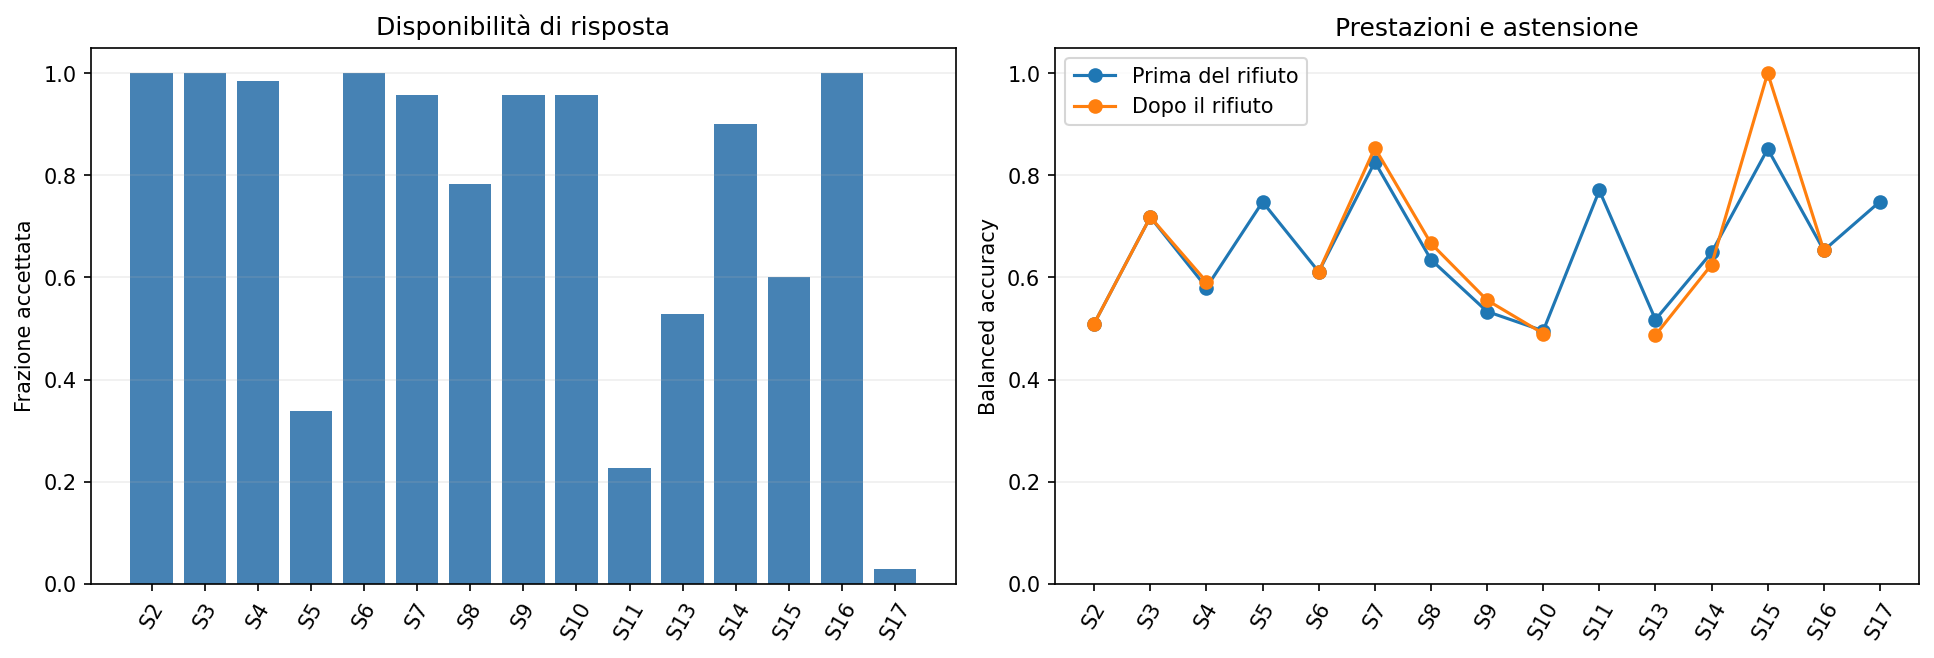

Il confronto usa label e prediction_raw della stessa procedura. Le prestazioni dopo il rifiuto riguardano un sottoinsieme selezionato e vanno lette insieme alla quota di finestre accettate.


In [14]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from IPython.display import display, Image, Markdown
from sklearn.metrics import accuracy_score, recall_score

results_dir = w.root(c) / "results"

pred = pd.read_csv(results_dir / "uncertainty_predictions.csv")

with (results_dir / "uncertainty_splits.json").open(
    "r", encoding="utf-8"
) as f:
    splits = json.load(f)

accepted_text = pred["accepted"].astype(str).str.strip().str.lower()
if not accepted_text.isin(["true", "false"]).all():
    raise ValueError("Valori inattesi nella colonna accepted.")

pred["accepted"] = accepted_text.eq("true")
pred["correct"] = pred["label"].eq(pred["prediction_raw"])

classes = np.array([1, 2, 3])
names = {1: "Baseline", 2: "Stress", 3: "Amusement"}

thresholds = {
    int(item["test_subject"]): item["threshold_on_raw_probabilities"]
    for item in splits
}

def evaluate_subset(frame):
    if frame.empty:
        return np.nan, np.nan, 0

    accuracy = accuracy_score(frame["label"], frame["prediction_raw"])
    present = set(frame["label"].unique())
    missing_count = len(set(classes) - present)

    ba = (
        recall_score(
            frame["label"],
            frame["prediction_raw"],
            labels=classes,
            average="macro",
            zero_division=0,
        )
        if missing_count == 0 else np.nan
    )
    return accuracy, ba, missing_count

subject_rows = []
class_rows = []

for sid, group in pred.groupby("subject_id"):
    accepted = group.loc[group["accepted"]]

    acc_before, ba_before, _ = evaluate_subset(group)
    acc_after, ba_after, missing_count = evaluate_subset(accepted)

    subject_rows.append({
        "subject_id": int(sid),
        "threshold": thresholds.get(int(sid), np.nan),
        "n_total": len(group),
        "n_accepted": len(accepted),
        "n_rejected": len(group) - len(accepted),
        "acceptance": len(accepted) / len(group),
        "accuracy_before": acc_before,
        "accuracy_after": acc_after,
        "delta_accuracy": acc_after - acc_before,
        "BA_before": ba_before,
        "BA_after": ba_after,
        "delta_BA": ba_after - ba_before,
        "missing_classes_after": missing_count,
    })

    for label in classes:
        original = group.loc[group["label"].eq(label)]
        retained = original.loc[original["accepted"]]

        class_rows.append({
            "subject_id": int(sid),
            "class": names[label],
            "n_total": len(original),
            "n_accepted": len(retained),
            "acceptance": (
                len(retained) / len(original) if len(original) else np.nan
            ),
            "recall_before": (
                original["correct"].mean() if len(original) else np.nan
            ),
            "recall_after": (
                retained["correct"].mean() if len(retained) else np.nan
            ),
        })

rejection_subjects = pd.DataFrame(subject_rows)
rejection_classes = pd.DataFrame(class_rows)

display(Markdown("### Rifiuto: risultati per soggetto"))
display(
    rejection_subjects.style.format({
        "threshold": "{:.3f}",
        **{
            column: "{:.1%}"
            for column in [
                "acceptance", "accuracy_before", "accuracy_after",
                "delta_accuracy", "BA_before", "BA_after", "delta_BA",
            ]
        },
    }, na_rep="N/D").hide(axis="index")
)

display(Markdown("### Accettazione e recall per soggetto e classe"))
display(
    rejection_classes.style.format({
        "acceptance": "{:.1%}",
        "recall_before": "{:.1%}",
        "recall_after": "{:.1%}",
    }, na_rep="N/D").hide(axis="index")
)

# Riepilogo per classe: conteggi aggregati sulle finestre.
class_summary = rejection_classes.groupby("class")[
    ["n_total", "n_accepted"]
].sum()
class_summary["acceptance"] = (
    class_summary["n_accepted"] / class_summary["n_total"]
)

display(Markdown("### Disponibilità di risposta per classe"))
display(class_summary.style.format({"acceptance": "{:.1%}"}))

# Confronto medio sullo stesso insieme di soggetti valutabili prima/dopo.
eligible = rejection_subjects.dropna(subset=["BA_before", "BA_after"])

paired_summary = pd.DataFrame({
    "metric": ["Accuracy", "Balanced accuracy"],
    "mean_before": [
        eligible["accuracy_before"].mean(),
        eligible["BA_before"].mean(),
    ],
    "mean_after": [
        eligible["accuracy_after"].mean(),
        eligible["BA_after"].mean(),
    ],
    "n_subjects": [len(eligible), len(eligible)],
})

display(Markdown(
    "### Confronto medio sugli stessi soggetti\n"
    "Include soltanto soggetti con tutte le classi presenti dopo il rifiuto. "
    "Controllare quanti soggetti restano: questo riepilogo può essere selettivo."
))
display(
    paired_summary.style.format({
        "mean_before": "{:.1%}",
        "mean_after": "{:.1%}",
    }, na_rep="N/D").hide(axis="index")
)

# Grafici per soggetto.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(rejection_subjects))
labels = rejection_subjects["subject_id"].map(lambda s: f"S{s}")

axes[0].bar(x, rejection_subjects["acceptance"], color="steelblue")
axes[0].set(
    xticks=x, xticklabels=labels, ylim=(0, 1.05),
    ylabel="Frazione accettata", title="Disponibilità di risposta",
)

axes[1].plot(
    x, rejection_subjects["BA_before"], "o-", label="Prima del rifiuto"
)
axes[1].plot(
    x, rejection_subjects["BA_after"], "o-", label="Dopo il rifiuto"
)
axes[1].set(
    xticks=x, xticklabels=labels, ylim=(0, 1.05),
    ylabel="Balanced accuracy", title="Prestazioni e astensione",
)
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    image_data = buffer.getvalue()
plt.close(fig)
display(Image(data=image_data))

print(
    "Il confronto usa label e prediction_raw della stessa procedura. "
    "Le prestazioni dopo il rifiuto riguardano un sottoinsieme selezionato "
    "e vanno lette insieme alla quota di finestre accettate."
)

In [15]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display, Markdown
from src.wesad_io import read_questionnaire
from src.self_reports import parse_self_reports, analyze
from src.fusion import comparison_tables

with (w.root(c) / "protocol_lock.json").open("r", encoding="utf-8") as f:
    saved_config = json.load(f)["config"]

raw_dir = Path(saved_config["dataset"]["raw_dir"])
questionnaire_files = sorted(raw_dir.rglob("S*_quest.csv"))

checks = []
parsed_frames = []

def error_message(exc):
    # Evita di mostrare percorsi assoluti nei messaggi diagnostici.
    message = str(exc).replace(str(raw_dir), "[dataset]")
    for file in questionnaire_files:
        message = message.replace(str(file), file.name)
    return f"{type(exc).__name__}: {message}"

for path in questionnaire_files:
    try:
        parsed = parse_self_reports(path)

        expected_subject = int(path.name.split("_")[0][1:])
        actual_subjects = set(parsed["subject_id"].astype(int))

        if actual_subjects != {expected_subject}:
            raise ValueError(
                f"ID interno {actual_subjects} diverso dal nome file "
                f"S{expected_subject}"
            )

        parsed_frames.append(parsed)

        checks.append({
            "file": path.name,
            "status": "OK",
            "episodes": len(parsed),
            "error": "",
        })

    except Exception as exc:
        checks.append({
            "file": path.name,
            "status": "ERROR",
            "episodes": None,
            "error": error_message(exc),
        })

        display(Markdown(f"**File da controllare: `{path.name}`**"))

        try:
            questionnaire = read_questionnaire(path)
            relevant_rows = [
                row for row in questionnaire["rows"]
                if row and (
                    "SUBJ" in row[0].upper()
                    or "ORDER" in row[0].upper()
                )
            ]
            for row in relevant_rows:
                print(repr(row))
        except Exception as read_error:
            print("Errore di lettura:", error_message(read_error))

questionnaire_check = pd.DataFrame(checks)

if not checks:
    print("Nessun questionario trovato nella cartella del dataset configurata.")
else:
    display(Markdown("### Esito della lettura dei questionari"))
    display(questionnaire_check)

    all_readable = questionnaire_check["status"].eq("OK").all()

    if not all_readable:
        print(
            "Analisi self-report non eseguita: correggere prima i file "
            "o il parser sulla base delle righe diagnostiche. "
            "Non vengono eliminati automaticamente i soggetti problematici."
        )
    else:
        questionnaire_scores = pd.concat(parsed_frames, ignore_index=True)

        expected = set(saved_config["dataset"]["expected_subjects"])
        observed = set(questionnaire_scores["subject_id"].astype(int))

        print("Soggetti attesi senza questionario:", sorted(expected - observed))
        print("Soggetti aggiuntivi:", sorted(observed - expected))

        duplicates = questionnaire_scores.duplicated(
            ["subject_id", "condition"], keep=False
        )

        if duplicates.any():
            display(questionnaire_scores.loc[duplicates])
            raise ValueError("Questionari duplicati per soggetto e condizione.")

        tables_for_reports = w.load_tables(c)
        paired_features = comparison_tables(
            tables_for_reports, paired_only=True
        )["early_fusion"]

        try:
            scores, condition_summary, correlations = analyze(
                raw_dir, paired_features
            )
        except Exception as exc:
            print(
                "File leggibili, ma analisi non completata:",
                error_message(exc),
            )
        else:
            display(Markdown("### Punteggi per soggetto e condizione"))
            display(scores)

            display(Markdown("### Riepilogo dei punteggi per condizione"))
            display(condition_summary)

            display(Markdown(
                "### Correlazioni esplorative tra feature e stress riferito"
            ))

            if correlations.empty:
                print(
                    "Nessuna correlazione calcolabile: verificare feature "
                    "disponibili, variabilità dei punteggi e numerosità."
                )
            else:
                display(correlations)

            print(
                "Punteggi calcolati secondo il parser attuale: verificare "
                "item e codifica con il README originale prima di interpretarli. "
                "Le correlazioni sono descrittive, a livello soggetto/condizione; "
                "non sono prove causali e non usano le finestre come risposte "
                "indipendenti ai questionari."
            )

### Esito della lettura dei questionari

,file,status,episodes,error
0,S10_quest.csv,OK,5,
1,S11_quest.csv,OK,5,
2,S13_quest.csv,OK,5,
3,S14_quest.csv,OK,5,
4,S15_quest.csv,OK,5,
5,S16_quest.csv,OK,5,
6,S17_quest.csv,OK,5,
7,S2_quest.csv,OK,5,
8,S3_quest.csv,OK,5,
9,S4_quest.csv,OK,5,


Soggetti attesi senza questionario: []
Soggetti aggiuntivi: []


### Punteggi per soggetto e condizione

,subject_id,episode_order,condition,label,panas_positive_sum,panas_negative_sum,stressed_item,frustrated_item,happy_item,sad_item,...,sam_missing_items,sssq_standalone_item_1,sssq_standalone_item_2,sssq_standalone_item_3,sssq_standalone_item_4,sssq_standalone_item_5,sssq_standalone_item_6,sssq_annoyed_from_panas,sssq_angry_from_panas,sssq_irritated_from_panas
0,10,0,Base,1,18.0,11.0,1.0,1.0,2.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10,1,Fun,3,26.0,10.0,1.0,1.0,4.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,2,Medi 1,4,14.0,10.0,1.0,1.0,2.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10,3,TSST,2,25.0,32.0,4.0,3.0,1.0,1.0,...,0,3.0,2.0,2.0,3.0,3.0,2.0,3.0,2.0,3.0
4,10,4,Medi 2,4,14.0,12.0,2.0,1.0,2.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,9,0,Base,1,27.0,14.0,2.0,1.0,4.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71,9,1,TSST,2,36.0,16.0,2.0,2.0,3.0,1.0,...,0,3.0,3.0,4.0,5.0,2.0,1.0,1.0,1.0,2.0
72,9,2,Medi 1,4,19.0,10.0,1.0,1.0,4.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
73,9,3,Fun,3,24.0,11.0,1.0,1.0,3.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Riepilogo dei punteggi per condizione

,condition,panas_positive_sum_count,panas_positive_sum_mean,panas_positive_sum_std,panas_negative_sum_count,panas_negative_sum_mean,panas_negative_sum_std,stressed_item_count,stressed_item_mean,stressed_item_std,stai6_keyed_sum_count,stai6_keyed_sum_mean,stai6_keyed_sum_std,sam_valence_count,sam_valence_mean,sam_valence_std,sam_arousal_count,sam_arousal_mean,sam_arousal_std
0,Base,15,25.466667,6.209056,15,12.266667,2.086236,15,1.533333,0.516398,15,10.800000,2.007130,15,6.666667,0.899735,15,2.533333,0.915475
1,Fun,15,25.800000,5.267149,15,11.466667,2.199567,15,1.066667,0.258199,15,9.266667,2.086236,15,7.466667,0.639940,15,3.000000,1.603567
2,Medi 1,15,19.000000,4.326001,14,11.142857,1.561909,15,1.066667,0.258199,15,9.866667,2.503331,15,6.933333,1.032796,15,2.133333,1.457330
3,Medi 2,15,18.333333,5.899960,15,11.666667,2.870208,15,1.600000,0.736788,15,10.400000,3.018988,15,6.133333,1.684665,15,2.466667,1.407463
4,TSST,15,31.333333,4.864840,15,22.000000,6.600866,15,3.533333,1.060099,15,18.533333,2.099887,15,4.533333,1.641718,15,6.800000,1.820518


### Correlazioni esplorative tra feature e stress riferito

,label,feature,target,n_subjects,spearman_rho,inference
0,1,chest__ECG__mean_hr,stressed_item,15,0.154647,exploratory effect only; no p-value or causal ...
1,1,wrist__BVP__mean_pulse_rate,stressed_item,15,0.185577,exploratory effect only; no p-value or causal ...
2,1,chest__EDA__mean,stressed_item,15,0.030929,exploratory effect only; no p-value or causal ...
3,1,wrist__EDA__mean,stressed_item,15,-0.030929,exploratory effect only; no p-value or causal ...
4,2,chest__ECG__mean_hr,stressed_item,15,0.676943,exploratory effect only; no p-value or causal ...
5,2,wrist__BVP__mean_pulse_rate,stressed_item,15,0.527127,exploratory effect only; no p-value or causal ...
6,2,chest__EDA__mean,stressed_item,15,0.014797,exploratory effect only; no p-value or causal ...
7,2,wrist__EDA__mean,stressed_item,15,-0.009248,exploratory effect only; no p-value or causal ...
8,3,chest__ECG__mean_hr,stressed_item,15,-0.309295,exploratory effect only; no p-value or causal ...
9,3,wrist__BVP__mean_pulse_rate,stressed_item,15,0.061859,exploratory effect only; no p-value or causal ...


Punteggi calcolati secondo il parser attuale: verificare item e codifica con il README originale prima di interpretarli. Le correlazioni sono descrittive, a livello soggetto/condizione; non sono prove causali e non usano le finestre come risposte indipendenti ai questionari.


### Late fusion meno comparatore
Differenze positive favoriscono la late fusion. Gli intervalli sono esplorativi e non corretti per confronti multipli.

comparator,n_subjects,mean_BA_late,mean_BA_comparator,difference_pp,CI_low_pp,CI_high_pp,subjects_improved,subjects_worse,subjects_tied
Early fusion · logistica,15,73.3%,68.2%,+5.11,+0.59,+10.28,9,6,0
Polso · logistica,15,73.3%,66.1%,+7.21,+1.55,+12.64,11,4,0
Polso · random forest,15,73.3%,68.3%,+5.03,-4.31,+14.04,8,7,0


### Differenze appaiate per soggetto

comparison,subject_id,BA_late,BA_comparator,difference
Early fusion · logistica,2,55.3%,33.3%,+21.9%
Early fusion · logistica,3,79.8%,82.2%,-2.4%
Early fusion · logistica,4,66.7%,51.7%,+15.0%
Early fusion · logistica,5,77.5%,79.6%,-2.1%
Early fusion · logistica,6,93.3%,92.5%,+0.9%
Early fusion · logistica,7,76.0%,79.8%,-3.8%
Early fusion · logistica,8,79.8%,76.8%,+3.0%
Early fusion · logistica,9,82.0%,83.6%,-1.7%
Early fusion · logistica,10,59.9%,64.7%,-4.8%
Early fusion · logistica,11,89.6%,89.2%,+0.4%


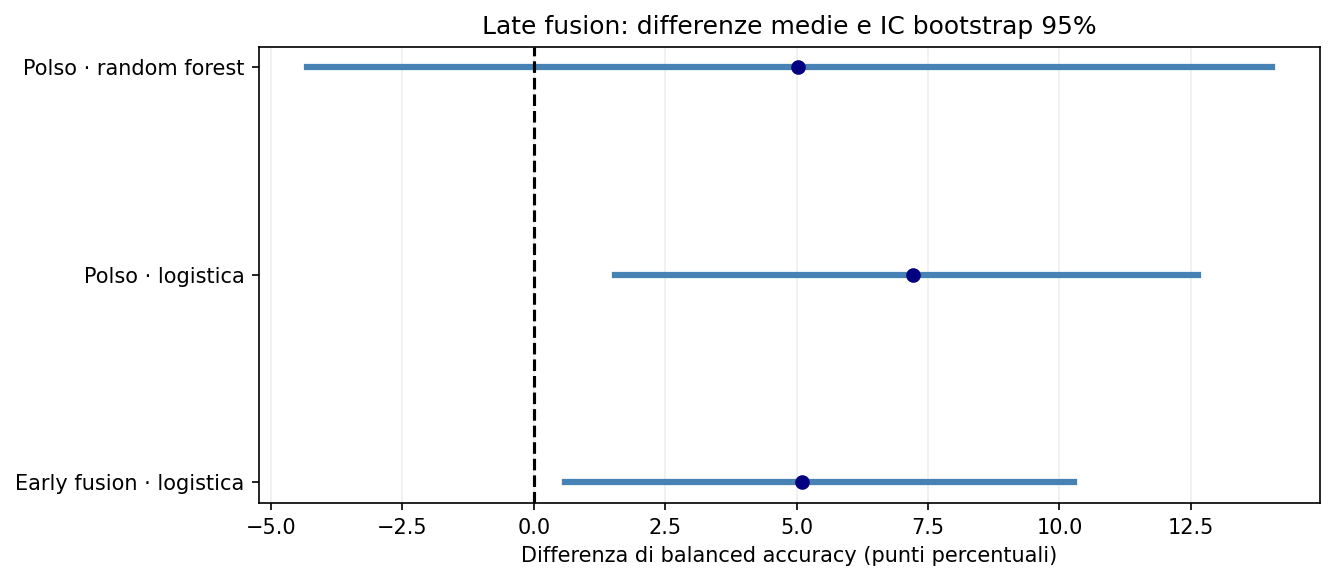

Se l'intervallo include zero, il confronto non dà un'indicazione chiara della direzione della differenza. Se è interamente positivo, il risultato favorisce descrittivamente la late fusion sotto questo bootstrap, ma resta esplorativo: non include nuovi addestramenti né validazione esterna.


In [16]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from IPython.display import display, Image, Markdown
from sklearn.metrics import recall_score

base_dir = w.root(c)
late_file = (
    base_dir / "exploratory" / "results"
    / "late_fusion_both_present_predictions.csv"
)

comparators = {
    "Early fusion · logistica": (
        base_dir / "results"
        / "confirmatory_early_fusion_logistic_regression_predictions.csv"
    ),
    "Polso · logistica": (
        base_dir / "results"
        / "confirmatory_wrist_logistic_regression_predictions.csv"
    ),
    "Polso · random forest": (
        base_dir / "results"
        / "confirmatory_wrist_random_forest_predictions.csv"
    ),
}

def read_predictions(path):
    if not path.is_file():
        raise FileNotFoundError(path)

    frame = pd.read_csv(path)
    required = ["subject_id", "window_id", "label", "p_1", "p_2", "p_3"]

    if not set(required).issubset(frame.columns):
        raise ValueError(f"Colonne mancanti in {path.name}")

    if frame.duplicated(["subject_id", "window_id"]).any():
        raise ValueError(f"Finestre duplicate in {path.name}")

    p = frame[["p_1", "p_2", "p_3"]].to_numpy(dtype=float)
    if (
        not np.isfinite(p).all()
        or (p < 0).any()
        or (p > 1).any()
        or not np.allclose(p.sum(axis=1), 1)
    ):
        raise ValueError(f"Probabilità non valide in {path.name}")

    frame["prediction"] = np.array([1, 2, 3])[p.argmax(axis=1)]
    return frame

late = read_predictions(late_file)

rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000
comparison_rows = []
subject_rows = []

for name, path in comparators.items():
    other = read_predictions(path)

    merged = late[
        ["subject_id", "window_id", "label", "prediction"]
    ].merge(
        other[["subject_id", "window_id", "label", "prediction"]],
        on=["subject_id", "window_id"],
        how="outer",
        suffixes=("_late", "_other"),
        indicator=True,
        validate="one_to_one",
    )

    if not merged["_merge"].eq("both").all():
        raise ValueError(
            f"{name}: finestre diverse. Il confronto non viene effettuato "
            "su un sottoinsieme selezionato automaticamente."
        )

    if not merged["label_late"].eq(merged["label_other"]).all():
        raise ValueError(f"{name}: label discordanti tra i file.")

    local_rows = []

    for sid, group in merged.groupby("subject_id"):
        if set(group["label_late"]) != {1, 2, 3}:
            raise ValueError(f"{name}, S{sid}: manca una classe.")

        ba_late = recall_score(
            group["label_late"], group["prediction_late"],
            labels=[1, 2, 3], average="macro", zero_division=0,
        )
        ba_other = recall_score(
            group["label_other"], group["prediction_other"],
            labels=[1, 2, 3], average="macro", zero_division=0,
        )

        row = {
            "comparison": name,
            "subject_id": int(sid),
            "BA_late": ba_late,
            "BA_comparator": ba_other,
            "difference": ba_late - ba_other,
        }
        local_rows.append(row)
        subject_rows.append(row)

    local = pd.DataFrame(local_rows)
    differences = local["difference"].to_numpy()

    if len(differences) < 2:
        raise ValueError("Servono almeno due soggetti per il bootstrap.")

    bootstrap_means = differences[
        rng.integers(
            0, len(differences),
            size=(N_BOOTSTRAP, len(differences)),
        )
    ].mean(axis=1)

    low, high = np.quantile(bootstrap_means, [0.025, 0.975])

    comparison_rows.append({
        "comparator": name,
        "n_subjects": len(local),
        "mean_BA_late": local["BA_late"].mean(),
        "mean_BA_comparator": local["BA_comparator"].mean(),
        "difference_pp": 100 * differences.mean(),
        "CI_low_pp": 100 * low,
        "CI_high_pp": 100 * high,
        "subjects_improved": int((differences > 1e-12).sum()),
        "subjects_worse": int((differences < -1e-12).sum()),
        "subjects_tied": int((np.abs(differences) <= 1e-12).sum()),
    })

late_comparisons = pd.DataFrame(comparison_rows)
late_subject_differences = pd.DataFrame(subject_rows)

display(Markdown(
    "### Late fusion meno comparatore\n"
    "Differenze positive favoriscono la late fusion. "
    "Gli intervalli sono esplorativi e non corretti per confronti multipli."
))
display(
    late_comparisons.style.format({
        "mean_BA_late": "{:.1%}",
        "mean_BA_comparator": "{:.1%}",
        "difference_pp": "{:+.2f}",
        "CI_low_pp": "{:+.2f}",
        "CI_high_pp": "{:+.2f}",
    }).hide(axis="index")
)

display(Markdown("### Differenze appaiate per soggetto"))
display(
    late_subject_differences.style.format({
        "BA_late": "{:.1%}",
        "BA_comparator": "{:.1%}",
        "difference": "{:+.1%}",
    }).hide(axis="index")
)

fig, ax = plt.subplots(figsize=(9, 4))
for y, row in late_comparisons.iterrows():
    ax.plot(
        [row["CI_low_pp"], row["CI_high_pp"]],
        [y, y], color="steelblue", linewidth=3,
    )
    ax.scatter(row["difference_pp"], y, color="navy", zorder=3)

ax.axvline(0, color="black", linestyle="--")
ax.set(
    yticks=range(len(late_comparisons)),
    yticklabels=late_comparisons["comparator"],
    xlabel="Differenza di balanced accuracy (punti percentuali)",
    title="Late fusion: differenze medie e IC bootstrap 95%",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()

with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    image_data = buffer.getvalue()
plt.close(fig)
display(Image(data=image_data))

print(
    "Se l'intervallo include zero, il confronto non dà un'indicazione "
    "chiara della direzione della differenza. "
    "Se è interamente positivo, il risultato favorisce descrittivamente "
    "la late fusion sotto questo bootstrap, ma resta esplorativo: "
    "non include nuovi addestramenti né validazione esterna."
)

Gli ultimi output chiariscono tre aspetti: il rifiuto migliora poco le prestazioni e non funziona uniformemente tra soggetti; la late fusion è promettente; i problemi dei questionari sono ora identificati e circoscritti.
1. Rifiuto delle predizioni: beneficio modesto e selettivo
Nel confronto sui 12 soggetti che conservano tutte e tre le classi dopo il rifiuto:
Metrica media per soggetto	Prima	Dopo	Differenza
Accuracy	74,8%	78,2%	+3,4 punti
Balanced accuracy	63,2%	64,7%	+1,5 punti


Il miglioramento della balanced accuracy è contenuto. Inoltre, questa sintesi esclude S5, S11 e S17 perché, dopo il rifiuto, non hanno più esempi accettati di tutte le classi. Non va presentata come risultato rappresentativo di tutti i 15 soggetti.
I casi individuali mostrano perché:
- S17: accetta soltanto 2 finestre su 68. Il 100% di accuracy riguarda due finestre stress: non dimostra affidabilità generale.
- S11: accetta 15 finestre su 66, tutte stress. Baseline e amusement vengono interamente rifiutate.
- S5: accetta 21 finestre su 62, senza alcuna finestra amusement.
- S2 e S6: accettano tutte le finestre, ma il recall di amusement rimane 0%. Il meccanismo non riconosce quindi tutti gli errori come incerti.
- S13 e S14: l’accuracy aumenta, ma la balanced accuracy diminuisce. Il filtraggio cambia la composizione delle finestre e può penalizzare alcune classi.
Anche l’accettazione aggregata è diversa tra condizioni:
Classe	Accettate / totali	Accettazione
Baseline	408 / 550	74,2%
Stress	243 / 295	82,4%
Amusement	107 / 160	66,9%


Il sistema risponde più spesso sullo stress e meno su amusement. Questo contribuisce a spiegare perché l’accuracy sulle sole finestre accettate possa apparire migliore.
Le soglie variano da circa 0,339 a 0,783: sono determinate separatamente in ciascun fold usando soggetti di calibrazione diversi. La variabilità delle soglie contribuisce alle differenze di accettazione, insieme alla distribuzione dei punteggi sui soggetti di test.
Azione: mantieni il rifiuto come analisi esplorativa e descrivilo come compromesso fra prestazioni e disponibilità di risposta. Non abbassare le soglie di S17 o degli altri soggetti dopo aver visto il test. Un’eventuale revisione del metodo va valutata con una nuova procedura interna al training/calibrazione.
Puoi commentarlo così:
Il rifiuto produce un miglioramento medio contenuto della balanced accuracy nei soggetti che mantengono tutte le classi, ma comporta una disponibilità di risposta fortemente variabile. In alcuni soggetti elimina intere condizioni, mentre in altri accetta anche errori sistematici. Non emerge pertanto un beneficio uniforme dell’astensione.

2. Late fusion: ora hai un confronto appaiato informativo
La late fusion raggiunge una balanced accuracy media del 73,3%.
Comparatore	Differenza: late fusion − comparatore	IC bootstrap 95%	Soggetti migliorati
Early fusion, logistica	+5,11 punti	+0,59 a +10,28	9/15
Polso, logistica	+7,21 punti	+1,55 a +12,64	11/15
Polso, random forest	+5,03 punti	−4,31 a +14,04	8/15


I primi due intervalli sono interamente positivi: il confronto esplorativo favorisce la late fusion rispetto alle due regressioni logistiche.
Rispetto alla random forest al polso, invece, l’intervallo comprende zero: non emerge una direzione sufficientemente chiara.
La variabilità individuale resta importante. Rispetto alla random forest al polso, per esempio:
- S3 guadagna circa 32,2 punti;
- S16 perde circa 34,6 punti.
Quindi la late fusion non migliora tutte le persone.
Azione: aggiungi questi risultati alla discussione esplorativa del report. Non sostituire retrospettivamente il risultato principale del notebook 04. Gli intervalli sono condizionati alle predizioni già ottenute e non corretti per i tre confronti: il risultato merita conferma su dati indipendenti.
Commento suggerito:
La media delle probabilità dei modelli toracico e da polso mostra un vantaggio esplorativo rispetto alla regressione logistica applicata alla concatenazione delle feature e al solo polso. Non emerge invece un vantaggio chiaro rispetto alla random forest al polso. Le differenze individuali rimangono ampie.

In [17]:
from src import self_reports as sr
print("Parser permanente: intestazioni normalizzate; nessuna imputazione dei mancanti.")


Parser permanente: intestazioni normalizzate; nessuna imputazione dei mancanti.


In [18]:
from src.fusion import comparison_tables
from src.exploratory import write_report

exploratory_root = w.root(c) / "exploratory"
exploratory_results = exploratory_root / "results"
exploratory_results.mkdir(parents=True, exist_ok=True)

raw_dir = Path(c["dataset"]["raw_dir"])
questionnaire_files = sorted(raw_dir.rglob("S*_quest.csv"))

if not questionnaire_files:
    raise FileNotFoundError(f"Nessun questionario in {raw_dir}")

# Verifica tutti i questionari prima di avviare il riepilogo.
checks = []
for path in questionnaire_files:
    frame = sr.parse_self_reports(path)
    checks.append({
        "file": path.name,
        "subject_id": int(frame["subject_id"].iloc[0]),
        "episodes": len(frame),
        "missing_items": int(
            frame[
                ["panas_missing_items", "stai_missing_items", "sam_missing_items"]
            ].to_numpy().sum()
        ),
    })

questionnaire_audit = pd.DataFrame(checks)

if questionnaire_audit["subject_id"].duplicated().any():
    raise ValueError("Più questionari per lo stesso soggetto.")

expected = set(c["dataset"]["expected_subjects"])
observed = set(questionnaire_audit["subject_id"])

print("Soggetti attesi senza questionario:", sorted(expected - observed))
print("Soggetti aggiuntivi:", sorted(observed - expected))
display(questionnaire_audit)

tables = w.load_tables(c)
paired_features = comparison_tables(tables, paired_only=True)["early_fusion"]

scores, condition_summary, correlations = sr.analyze(
    raw_dir, paired_features
)

scores.to_csv(
    exploratory_results / "self_report_episode_scores.csv", index=False
)
condition_summary.to_csv(
    exploratory_results / "self_report_condition_summary.csv", index=False
)
correlations.to_csv(
    exploratory_results / "self_report_feature_correlations.csv", index=False
)
questionnaire_audit.to_csv(
    exploratory_results / "self_report_parsing_audit.csv", index=False
)

design = {
    "unit": "subject and experimental episode",
    "no_window_label_broadcast": True,
    "clinical_thresholds": False,
    "missing_policy": (
        "No imputation; a score is missing if a required item is missing. "
        "Other scores and episodes remain available."
    ),
    "scoring_status": (
        "Original parser item mapping retained; verify against dataset documentation."
    ),
    "feature_correlations": (
        "Subject-level feature medians within condition; descriptive Spearman rho."
    ),
    "n_subjects": int(scores["subject_id"].nunique()),
    "n_episodes": len(scores),
}

(exploratory_results / "self_report_design.json").write_text(
    json.dumps(design, indent=2), encoding="utf-8"
)

status_path = exploratory_results / "status.json"
status = (
    json.loads(status_path.read_text(encoding="utf-8"))
    if status_path.is_file() else {}
)
status["self_reports"] = {
    "status": "completed",
    "reason": None,
    "analysis_role": "exploratory",
    "missing_policy": design["missing_policy"],
    "scoring_status": design["scoring_status"],
}
status_path.write_text(
    json.dumps(status, indent=2), encoding="utf-8"
)

write_report(exploratory_root, status, synthetic=False)

display(Markdown("### Episodi con risposte mancanti"))
missing = scores[
    scores[
        ["panas_missing_items", "stai_missing_items", "sam_missing_items"]
    ].sum(axis=1).gt(0)
]
display(missing)

display(Markdown("### Punteggi per condizione: controllare anche le numerosità"))
display(condition_summary)

display(Markdown("### Correlazioni esplorative"))
display(correlations)

print("Self-report salvati e stato aggiornato. Nessun modello riaddestrato.")


Soggetti attesi senza questionario: []
Soggetti aggiuntivi: []


,file,subject_id,episodes,missing_items
0,S10_quest.csv,10,5,0
1,S11_quest.csv,11,5,0
2,S13_quest.csv,13,5,0
3,S14_quest.csv,14,5,0
4,S15_quest.csv,15,5,0
5,S16_quest.csv,16,5,0
6,S17_quest.csv,17,5,0
7,S2_quest.csv,2,5,0
8,S3_quest.csv,3,5,0
9,S4_quest.csv,4,5,0


### Episodi con risposte mancanti

,subject_id,episode_order,condition,label,panas_positive_sum,panas_negative_sum,stressed_item,frustrated_item,happy_item,sad_item,...,sam_missing_items,sssq_standalone_item_1,sssq_standalone_item_2,sssq_standalone_item_3,sssq_standalone_item_4,sssq_standalone_item_5,sssq_standalone_item_6,sssq_annoyed_from_panas,sssq_angry_from_panas,sssq_irritated_from_panas
52,5,2,Medi 1,4,19.0,NaN,1.0,1.0,4.0,1.0,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Punteggi per condizione: controllare anche le numerosità

,condition,panas_positive_sum_count,panas_positive_sum_mean,panas_positive_sum_std,panas_negative_sum_count,panas_negative_sum_mean,panas_negative_sum_std,stressed_item_count,stressed_item_mean,stressed_item_std,stai6_keyed_sum_count,stai6_keyed_sum_mean,stai6_keyed_sum_std,sam_valence_count,sam_valence_mean,sam_valence_std,sam_arousal_count,sam_arousal_mean,sam_arousal_std
0,Base,15,25.466667,6.209056,15,12.266667,2.086236,15,1.533333,0.516398,15,10.800000,2.007130,15,6.666667,0.899735,15,2.533333,0.915475
1,Fun,15,25.800000,5.267149,15,11.466667,2.199567,15,1.066667,0.258199,15,9.266667,2.086236,15,7.466667,0.639940,15,3.000000,1.603567
2,Medi 1,15,19.000000,4.326001,14,11.142857,1.561909,15,1.066667,0.258199,15,9.866667,2.503331,15,6.933333,1.032796,15,2.133333,1.457330
3,Medi 2,15,18.333333,5.899960,15,11.666667,2.870208,15,1.600000,0.736788,15,10.400000,3.018988,15,6.133333,1.684665,15,2.466667,1.407463
4,TSST,15,31.333333,4.864840,15,22.000000,6.600866,15,3.533333,1.060099,15,18.533333,2.099887,15,4.533333,1.641718,15,6.800000,1.820518


### Correlazioni esplorative

,label,feature,target,n_subjects,spearman_rho,inference
0,1,chest__ECG__mean_hr,stressed_item,15,0.154647,exploratory effect only; no p-value or causal ...
1,1,wrist__BVP__mean_pulse_rate,stressed_item,15,0.185577,exploratory effect only; no p-value or causal ...
2,1,chest__EDA__mean,stressed_item,15,0.030929,exploratory effect only; no p-value or causal ...
3,1,wrist__EDA__mean,stressed_item,15,-0.030929,exploratory effect only; no p-value or causal ...
4,2,chest__ECG__mean_hr,stressed_item,15,0.676943,exploratory effect only; no p-value or causal ...
5,2,wrist__BVP__mean_pulse_rate,stressed_item,15,0.527127,exploratory effect only; no p-value or causal ...
6,2,chest__EDA__mean,stressed_item,15,0.014797,exploratory effect only; no p-value or causal ...
7,2,wrist__EDA__mean,stressed_item,15,-0.009248,exploratory effect only; no p-value or causal ...
8,3,chest__ECG__mean_hr,stressed_item,15,-0.309295,exploratory effect only; no p-value or causal ...
9,3,wrist__BVP__mean_pulse_rate,stressed_item,15,0.061859,exploratory effect only; no p-value or causal ...


Self-report salvati e stato aggiornato. Nessun modello riaddestrato.


I self-report sono stati utilizzati per descrivere l’esperienza soggettiva nelle diverse condizioni sperimentali e per esplorare l’associazione tra stress riferito e caratteristiche fisiologiche. Per ciascuna condizione, le feature sono state aggregate mediante la mediana per soggetto e correlate con l’item di stress percepito tramite Spearman. I questionari non sono stati utilizzati come etichette di addestramento. Le associazioni sono considerate esplorative, data la numerosità ridotta e la molteplicità dei confronti.

In [21]:
required_variables = [
    "rejection_subjects",
    "rejection_classes",
    "late_comparisons",
    "late_subject_differences",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Esegui prima le celle del rifiuto e della late fusion. Mancano: "
        + ", ".join(missing_variables)
    )

results_dir = w.root(c) / "results"
reports_dir = w.root(c) / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Salva anche le verifiche aggiunte al notebook.
rejection_subjects.to_csv(
    results_dir / "rejection_subject_summary.csv", index=False
)
rejection_classes.to_csv(
    results_dir / "rejection_class_summary.csv", index=False
)
late_comparisons.to_csv(
    results_dir / "late_fusion_paired_comparisons.csv", index=False
)
late_subject_differences.to_csv(
    results_dir / "late_fusion_paired_subject_differences.csv", index=False
)

# Rigenera il report principale leggendo lo stato aggiornato.
report_result = w.report_stage(c, synthetic=False)

eligible = rejection_subjects.dropna(subset=["BA_before", "BA_after"])
n_all = len(rejection_subjects)
n_eligible = len(eligible)

def percent(value):
    return f"{100 * value:.1f}%"

lines = [
    "# Verifiche aggiuntive",
    "",
    "## Rifiuto delle predizioni",
    "",
    f"Soggetti valutati: {n_all}. Soggetti che conservano tutte le classi "
    f"dopo il rifiuto: {n_eligible}.",
    "",
]

if n_eligible:
    lines += [
        "Medie sugli stessi soggetti con tutte le classi ancora rappresentate:",
        "",
        f"- Accuracy: {percent(eligible['accuracy_before'].mean())} prima, "
        f"{percent(eligible['accuracy_after'].mean())} dopo.",
        f"- Balanced accuracy: {percent(eligible['BA_before'].mean())} prima, "
        f"{percent(eligible['BA_after'].mean())} dopo.",
        "",
    ]

lines += [
    "Le metriche dopo il rifiuto riguardano un sottoinsieme selezionato. "
    "I soggetti senza tutte le classi accettate non entrano nella precedente "
    "media, ma restano documentati nelle tabelle per soggetto.",
    "",
    "| Classe | Finestre totali | Accettate | Accettazione |",
    "|---|---:|---:|---:|",
]

availability = rejection_classes.groupby("class")[
    ["n_total", "n_accepted"]
].sum()

for name, row in availability.iterrows():
    rate = row["n_accepted"] / row["n_total"]
    lines.append(
        f"| {name} | {int(row['n_total'])} | "
        f"{int(row['n_accepted'])} | {percent(rate)} |"
    )

lines += [
    "",
    "L'accettazione non garantisce correttezza. Alcuni soggetti perdono intere "
    "classi; altri mantengono errori anche quando tutte le finestre sono accettate. "
    "Il rifiuto non mostra quindi un beneficio uniforme.",
    "",
    "## Late fusion: confronti appaiati esplorativi",
    "",
    "| Comparatore | Differenza BA, punti percentuali | IC bootstrap 95% |",
    "|---|---:|---|",
]

for _, row in late_comparisons.iterrows():
    lines.append(
        f"| {row['comparator']} | {row['difference_pp']:+.2f} | "
        f"[{row['CI_low_pp']:+.2f}, {row['CI_high_pp']:+.2f}] |"
    )

lines += [
    "",
    "Differenze positive favoriscono la late fusion. Gli intervalli sono "
    "condizionati alle predizioni LOSO già ottenute, non includono nuovi "
    "addestramenti e non sono corretti per confronti multipli. "
    "I risultati rimangono esplorativi.",
    "",
    "## Questionari",
    "",
    f"Sono stati elaborati {scores['subject_id'].nunique()} soggetti "
    f"e {len(scores)} episodi.",
    "",
    "Il parser accetta le intestazioni identificative con o senza due punti. "
    "Le risposte mancanti non vengono imputate: soltanto i punteggi che "
    "richiedono tali risposte diventano mancanti. "
    "Le numerosità effettive sono riportate nei riepiloghi per punteggio.",
    "",
    "La codifica degli item mantiene quella del parser originale e deve essere "
    "verificata con la documentazione WESAD prima dell'interpretazione. "
    "Le correlazioni con le feature sono descrittive a livello soggetto/condizione, "
    "senza interpretazione causale.",
]

supplement = "\n".join(lines) + "\n"
supplement_path = reports_dir / "additional_checks.md"
supplement_path.write_text(supplement, encoding="utf-8")

# report_stage ha appena riscritto il report: l'appendice non si duplica
# rieseguendo questa cella.
report_path = reports_dir / "report.md"
main_text = report_path.read_text(encoding="utf-8")

report_path.write_text(
    main_text + "\n---\n\n" + supplement,
    encoding="utf-8",
)

display(Markdown(supplement))


# Verifiche aggiuntive

## Rifiuto delle predizioni

Soggetti valutati: 15. Soggetti che conservano tutte le classi dopo il rifiuto: 12.

Medie sugli stessi soggetti con tutte le classi ancora rappresentate:

- Accuracy: 74.8% prima, 78.2% dopo.
- Balanced accuracy: 63.2% prima, 64.7% dopo.

Le metriche dopo il rifiuto riguardano un sottoinsieme selezionato. I soggetti senza tutte le classi accettate non entrano nella precedente media, ma restano documentati nelle tabelle per soggetto.

| Classe | Finestre totali | Accettate | Accettazione |
|---|---:|---:|---:|
| Amusement | 160 | 107 | 66.9% |
| Baseline | 550 | 408 | 74.2% |
| Stress | 295 | 243 | 82.4% |

L'accettazione non garantisce correttezza. Alcuni soggetti perdono intere classi; altri mantengono errori anche quando tutte le finestre sono accettate. Il rifiuto non mostra quindi un beneficio uniforme.

## Late fusion: confronti appaiati esplorativi

| Comparatore | Differenza BA, punti percentuali | IC bootstrap 95% |
|---|---:|---|
| Early fusion · logistica | +5.11 | [+0.59, +10.28] |
| Polso · logistica | +7.21 | [+1.55, +12.64] |
| Polso · random forest | +5.03 | [-4.31, +14.04] |

Differenze positive favoriscono la late fusion. Gli intervalli sono condizionati alle predizioni LOSO già ottenute, non includono nuovi addestramenti e non sono corretti per confronti multipli. I risultati rimangono esplorativi.

## Questionari

Sono stati elaborati 15 soggetti e 75 episodi.

Il parser accetta le intestazioni identificative con o senza due punti. Le risposte mancanti non vengono imputate: soltanto i punteggi che richiedono tali risposte diventano mancanti. Le numerosità effettive sono riportate nei riepiloghi per punteggio.

La codifica degli item mantiene quella del parser originale e deve essere verificata con la documentazione WESAD prima dell'interpretazione. Le correlazioni con le feature sono descrittive a livello soggetto/condizione, senza interpretazione causale.


In [20]:
from IPython.display import display, Markdown
import json
paths=sorted((w.root(c)/'results').glob('block_permutation_*/result.json'))
if not paths:
    print('Randomizzazione training a blocchi non ancora eseguita: nessun p-value disponibile.')
else:
    paragraphs=['## Randomizzazione training a blocchi (condizionale)']
    for path in paths:
        result=json.loads(path.read_text(encoding='utf-8'))
        paragraphs.append(f"{path.parent.name}: BA={result['observed_BA']:.4f}; p={result['p_value']:.4f}; repliche={result['n_permutations']}.")
        paragraphs.append(result['interpretation'])
    section='\n\n'.join(paragraphs)
    display(Markdown(section))
    (w.root(c)/'reports/block_permutation_summary.md').write_text(section,encoding='utf-8')


Randomizzazione training a blocchi non ancora eseguita: nessun p-value disponibile.


## Overall discussion and limitations

### Primary classification results

The project compares chest, wrist, and combined physiological signals for
classification of **baseline, stress, and amusement** in held-out WESAD
participants.

Primary comparisons use **1,005 common valid windows from 15 participants**.
The main endpoint is balanced accuracy averaged equally across participants,
with hyperparameter tuning restricted to training participants.

Among the original primary configurations, balanced accuracy ranges from
**63.05% to 68.29%**, compared with **33.33%** for the majority classifier.

Wrist random forest has the highest observed mean balanced accuracy
(**68.29%**), followed closely by early-fusion logistic regression
(**68.21%**). This small difference does not establish a definitive winner.

The paired early-fusion versus wrist comparisons include zero in their
conditional confidence intervals. They do not establish a systematic
early-fusion advantage, equivalence between configurations, or wrist
noninferiority.

### Secondary tasks

Binary classification produces higher observed scores:

| Task | Configuration | Mean balanced accuracy |
|---|---|---:|
| Stress versus non-stress | Wrist logistic regression | 90.33% |
| Baseline versus stress | Wrist logistic regression | 91.22% |

These results suggest that distinguishing the laboratory stress condition
is easier than separating all three primary conditions.

However, binary tasks address different questions and do not replace the
three-class evaluation. A high binary score does not demonstrate equally
good recognition of amusement or continuous perceived stress.

Modality-specific availability analyses produce results close to the
corresponding primary configurations. Because each modality can use
different windows, these analyses are not matched-sample sensor comparisons.

### Selective prediction: limited and heterogeneous benefit

The rejection procedure accepts **758 of 1,005 windows: 75.42%**.

Acceptance differs by class:

| Class | Accepted / total windows | Acceptance |
|---|---:|---:|
| Baseline | 408 / 550 | 74.2% |
| Stress | 243 / 295 | 82.4% |
| Amusement | 107 / 160 | 66.9% |

Among the **12 participants retaining accepted windows from all three
classes**, mean performance changes as follows:

| Metric | Before rejection | After rejection |
|---|---:|---:|
| Accuracy | 74.8% | 78.2% |
| Balanced accuracy | 63.2% | 64.7% |

The balanced-accuracy improvement is modest. This summary excludes S5,
S11, and S17 because at least one class disappears after rejection.
It must not be presented as an improvement estimate covering all
15 participants.

Individual examples reveal important limitations:

- **S17:** only 2 of 68 windows are accepted; both are stress windows.
- **S11:** 15 of 66 windows are accepted, all from the stress condition.
- **S5:** 21 of 62 windows are accepted, with no amusement windows retained.
- **S2 and S6:** every window is accepted, although amusement recall is 0%.
- **S13 and S14:** accuracy increases while balanced accuracy decreases.

A high accepted-window accuracy can therefore coexist with limited
availability, missing classes, or confidently incorrect predictions.

Thresholds range from approximately **0.339 to 0.783**, with three
calibration participants in each fold. Their variation reflects the
calibration samples, fitted models, and test-score distributions.

The procedure remains exploratory. Acceptance does not guarantee
correctness, and calibration on a small sample does not establish
uniform reliability for new individuals.

### Late fusion: promising exploratory evidence

Late fusion averages the probabilities from separate chest and wrist
logistic-regression models using fixed equal weights.

It achieves **73.32% mean balanced accuracy**.

| Comparator | Late fusion minus comparator | Conditional bootstrap 95% CI | Participants improved |
|---|---:|---|---:|
| Early-fusion logistic regression | +5.11 percentage points | [+0.59, +10.28] | 9/15 |
| Wrist logistic regression | +7.21 percentage points | [+1.55, +12.64] | 11/15 |
| Wrist random forest | +5.03 percentage points | [−4.31, +14.04] | 8/15 |

The first two intervals favor late fusion under this exploratory bootstrap.
The comparison with wrist random forest remains inconclusive.

Benefits are not uniform across participants. Relative to wrist random
forest, S3 improves by approximately **32.2 points**, whereas S16 decreases
by approximately **34.6 points**.

These comparisons are conditional on fitted predictions and are not
corrected for the three comparisons. They support further investigation
of late fusion, not its retrospective promotion to a definitive primary
winner.

### Self-report analyses

Self-report processing is complete for **15 participants and 75 episodes**.

Questionnaires are used to describe subjective experience across conditions
and to explore associations between reported stress and physiological
features. They are not used as classifier-training labels.

For these associations, physiological features are summarized using one
median per participant and condition. Spearman correlations therefore
operate at participant–condition level rather than treating every window
as an independent questionnaire observation.

During TSST, the stressed item has descriptive correlations of:

- **rho = 0.677** with chest mean heart rate.
- **rho = 0.527** with wrist mean pulse rate.
- **rho = 0.015** with chest EDA mean.
- **rho = −0.009** with wrist EDA mean.

These feature–self-report coefficients are exploratory and do not include
p-values or confidence intervals in this analysis. Statistical significance,
causality, or psychological validation of the classifier should not be
claimed from these values.

Missing questionnaire responses are not imputed. Only scores requiring
a missing item are unavailable; other scores and episodes remain usable.
Successful parsing does not itself validate questionnaire scoring, which
must be checked against the original dataset documentation.

Associations between self-reports and classifier outputs are addressed
separately in notebook 08.

### Statistical and methodological limitations

The confidence intervals resample participants conditional on the saved
LOSO predictions. They do not capture the full variability of a new
training procedure.

Further limitations include:

- A small laboratory sample without independent external validation.
- Overlapping windows that are not independent observations.
- Shared training participants across LOSO folds.
- Substantial variation between participants.
- Persistent difficulty recognizing amusement.
- Heuristic quality checks and physiological proxy features.
- Small calibration samples.
- Multiple exploratory models, thresholds, and comparisons.

Experimental conditions, subjective stress, and peripheral physiological
responses are related but distinct measurements. None should automatically
be treated as interchangeable with the others.

### Conclusion

The project demonstrates discrimination between laboratory conditions in
held-out WESAD participants, with particularly promising results for
binary stress classification and exploratory late fusion.

However, aggregate performance does not establish reliable behavior for
every participant or class. Selective prediction provides only a modest,
uneven benefit, and the available comparisons do not identify a
definitive overall winner.

Primary, secondary, and exploratory findings should remain separate.
External validation, improved individual reliability, and further analysis
of amusement errors are needed before extending the conclusions to
everyday stress monitoring or clinical applications.